# Fraction of time off treatment: Zhang cohort (abiraterone, mCRPC)

Does the AT score predict the fraction of follow-up spent off treatment in the Zhang cohort? 
(`paper_figures/patient_fits/Zhang_first_cycle_published.csv`), AT score = `calc_delta_benefit(kappa = 0.2)`, and the manuscript's patient filters (N = 13).

**Endpoints** (`analysis/holiday_fraction_utils.py`): the off fraction of the whole record from the first drug-on row; the same counting the pre-treatment lead-in as off (13 of 17 Zhang files begin with off-drug rows before abiraterone starts); and the off fraction after the first cycle (restart of treatment to the end of the record).


In [1]:
import os, sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
warnings.filterwarnings("ignore")
sys.path.append("../analysis"); sys.path.append("../utils"); sys.path.append("../patients")
import zhang_published_pipeline as zp
import zhang_holiday_published_fits as zh
try:
    plt.style.use(["classic", "../paper_figures/paper.mplstyle"])
except Exception:
    plt.style.use("classic")
plt.rcParams["font.size"] = 12; plt.rcParams["figure.facecolor"] = "white"
OUT = "../analysis"
BLUE, GREY = "#0044AA", "#777777"


## Manuscript statistics from the published fits

In [2]:
fits = pd.read_csv(zp.PUBLISHED_FITS)
res, T, M = zp.evaluate(fits)
print("Published Zhang fits: %d patients; analysed N = %d (events = %d)" % (len(fits), res["N"], res["events"]))
print("AT score vs clinical TTP: Spearman rho = %.3f, P = %.4f" % (res["rho_AT"], res["p_rho_AT"]))
c = res["cox_AT"]; print("Univariable Cox HR (per SD) = %.2f (95%% CI %.2f-%.2f), P = %.3f" % (c["HR"], c["lo"], c["hi"], c["p"]))
if res["OS_logrank"] is not None:
    print("OS log-rank (median split), N = %d: AT score P = %.3f, eTTP P = %.3f" % (res["N_OS"], res["OS_logrank"]["AT_Score"], res["OS_logrank"]["Clinical_Preds"]))
else:
    print("OS statistics skipped: the patient-level outcomes workbook is not distributed with the repository")
# the published fit table is reproduced by refitting with the published settings
ref = zp.refit_published().set_index("PatientId"); pub = fits.set_index("PatientId")
print("refit with published settings vs published table: max |d turnover| = %.1e, max |d K| = %.1e" % ((ref.turnover - pub.turnover).abs().max(), (ref.K - pub.K).abs().max()))

Published Zhang fits: 17 patients; analysed N = 13 (events = 13)
AT score vs clinical TTP: Spearman rho = 0.764, P = 0.0024
Univariable Cox HR (per SD) = 0.41 (95% CI 0.16-1.07), P = 0.068
OS log-rank (median split), N = 13: AT score P = 0.037, eTTP P = 0.029
refit with published settings vs published table: max |d turnover| = 1.1e-16, max |d K| = 0.0e+00


## AT score vs fraction of follow-up off treatment

Patient sets: **A** = the manuscript's N = 13; **B** = progression and R^2 filters without the requirement that clinical TTP can be computed; **C** = A without the four patients whose first-cycle window contains a single PSA point (their turnover stays at the optimiser's lower bound, so they share an AT score of about 0.254 and carry no data);
**D** = B without fits above the AT-score pole; **E** = all 17 patients, no filters. Spearman P values are checked by permutation; CIs are 95% bootstrap intervals.

In [3]:
R, A = zh.main()
pd.set_option("display.max_colwidth", 70); pd.set_option("display.width", 220)
print(R.round(3).to_string(index=False))

                                    patient_set                                                          endpoint  N   rho  P_spearman  P_permutation  CI_lo  CI_hi
  A. Published filters (N=13 of the manuscript)                              whole record, from first drug-on row 13 0.236       0.437          0.443 -0.451  0.788
  A. Published filters (N=13 of the manuscript) whole record, from first record (pre-treatment rows count as off) 13 0.247       0.415          0.424 -0.445  0.792
  A. Published filters (N=13 of the manuscript)                            after the first cycle (restart to end) 13 0.424       0.149          0.149 -0.222  0.857
B. Progression + R2 filters, no TTP requirement                              whole record, from first drug-on row 15 0.271       0.328          0.335 -0.375  0.758
B. Progression + R2 filters, no TTP requirement whole record, from first record (pre-treatment rows count as off) 15 0.339       0.216          0.220 -0.291  0.809
B. Progression +

## Scatter plots (manuscript patient set)

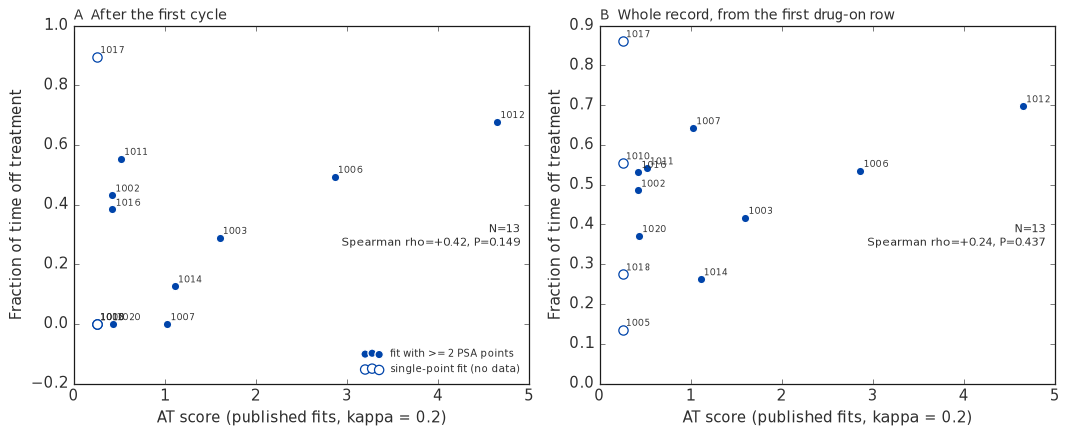

In [4]:
S = A[A.in_published_N13]
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for ax, col, ttl in zip(axs, ["off_after_C1", "off_from_first_drug_on"], ["A  After the first cycle", "B  Whole record, from the first drug-on row"]):
    s = S[["AT_Score", col, "n_pts"]].dropna()
    rho, p = spearmanr(s.AT_Score, s[col])
    one = s.n_pts == 1
    ax.scatter(s.AT_Score[~one], s[col][~one], color=BLUE, s=45, zorder=3, edgecolor="w", label="fit with >= 2 PSA points")
    ax.scatter(s.AT_Score[one], s[col][one], facecolor="w", edgecolor=BLUE, s=55, zorder=3, label="single-point fit (no data)")
    for pid, r in S.loc[s.index].iterrows(): ax.annotate(int(pid), (r.AT_Score, r[col]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.set_xlabel("AT score (published fits, kappa = 0.2)"); ax.set_ylabel("Fraction of time off treatment"); ax.set_title(ttl, fontsize=11, loc="left")
    ax.text(0.98, 0.45, "N=%d\nSpearman rho=%+.2f, P=%.3f" % (len(s), rho, p), transform=ax.transAxes, va="top", ha="right", fontsize=9, bbox=dict(fc="w", ec="none", alpha=.85))
axs[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig(f"{OUT}/holiday_zhang_scatter.png", dpi=150); plt.show()

## Summary

**Reference (manuscript statistics, same fits, N = 13).** AT score vs clinical TTP: Spearman rho = 0.76 (P = 0.0024); univariable Cox HR 0.41 (0.16-1.07), P = 0.068.

**AT score vs fraction of follow-up off treatment (published fits, manuscript patients).**
* After the first cycle: rho = +0.42 (P = 0.149; 95% CI -0.22 to +0.86), N = 13.
* Whole record from the first drug-on row: rho = +0.24 (P = 0.437; 95% CI -0.45 to +0.79), N = 13.
* Whole record counting the pre-treatment lead-in as off: rho = +0.25 (P = 0.415; 95% CI -0.44 to +0.79), N = 13.

Across the five patient sets and three endpoints rho ranges from +0.21 to +0.47 and the smallest Spearman P is 0.060; no set reaches P < .05. The confidence intervals are wide (N = 9-17), so a moderate association cannot be excluded, but there is no evidence for one in this cohort.
